## **Lab 3: Spectral Representation**

The goal of this lab is to connect the time-domain signal you have been working with to its frequency-domain representation. The theory summary on spectrum representation introduces two complementary views of the same signal:

- the Fourier transform, which gives the frequency content of a signal segment, and
- the spectrogram, which shows how that content changes over time.

In this lab we will first compute the magnitude spectrum of a short fragment of the reference audio, then we will compute a spectrogram of the whole sound. The goal is not only to produce plots, but also to interpret them and relate them back to the sound you hear.

A periodic signal contains energy at its fundamental frequency and at its harmonics. When the signal is not perfectly periodic, the spectrum becomes less sharp and the energy spreads around those frequencies. In a short fragment, the FFT gives a snapshot of the dominant components. In a longer signal, the spectrogram shows how these components evolve over time.

In [2]:
import numpy as np
import librosa
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Audio, display
#----
from util import load_audio, plot_signals, plot_spectrogram, plot_spectrum

We will use the same reference sound from the previous labs. If you have your own audio file in a cloned repository, you can point the path there; otherwise the notebook will use the bundled reference file.

### 1. Spectrum Analysis

This section show how to compute the spectrum and the spectrogram of a sound

In [4]:
# Clone your own repository and point reference_path to your own audio file.
# \!git clone https://github.com/your-username/sis1_name.git
# reference_path = Path('./sis1_name/your_file.wav')

reference_path = Path('../audio_elegido/celtic_harp_D5.wav')
reference_audio, fs = load_audio(reference_path)
print(f'Using audio file: {reference_path}')

display(Audio(reference_audio, rate=fs))

Using audio file: ../audio_elegido/celtic_harp_D5.wav


#### 1.1 Fourier transform of a short fragment

The first step is to look at a short fragment of the sound and compute its magnitude spectrum using the FFT. This gives a snapshot of the strongest frequency components present in that fragment.

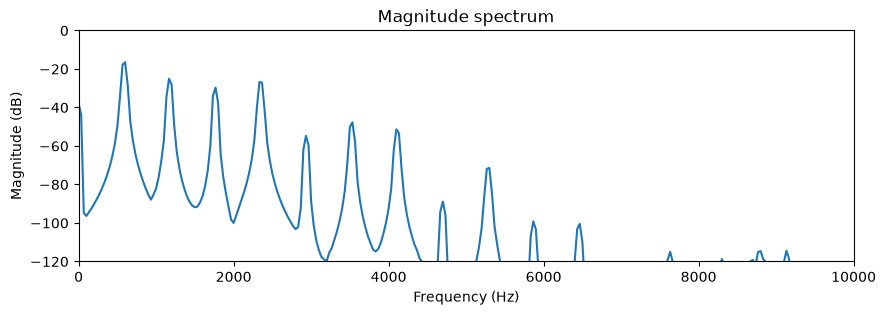

In [13]:
start = int(0.25 * fs)
end = int(0.28 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

#### 1.2 Questions

1. What are the strongest peaks in the magnitude spectrum? To what harmonics do they correspond?
   - Around -20 dB. Al 0, 1, 2...

2. Do you see a fundamental frequency and its harmonics? How did you identify them?
   - Si, està al voltant dels 600 Hz, és el primer pic significatiu de la sèrie.

3. How would the spectrum change if the fragment were taken from a different part of the signal?
   - Doncs cambiaria la freqüència fonamental, i per tant l'espaiat entre pics. També la magnitud segons lo 'desgastada' que estigui la ona.

#### 1.3 Spectrogram of the whole sound

The FFT of one fragment gives a local snapshot, but a sound changes over time. A spectrogram shows how the frequency content evolves across the whole signal.

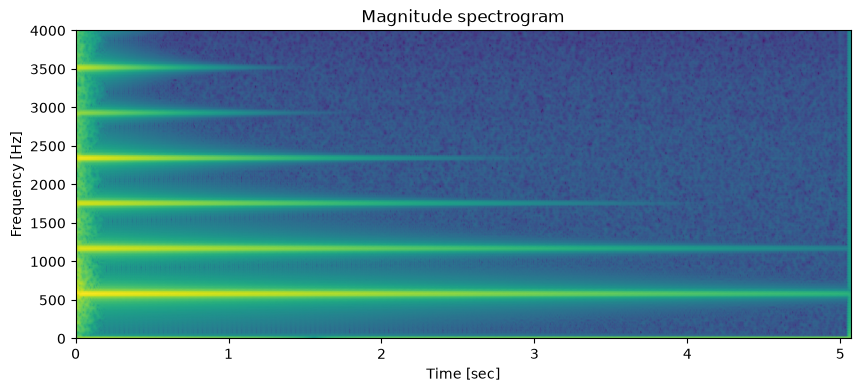

In [16]:
n_fft = 2048
hop_length = 256

ax = plot_spectrogram(reference_audio, sr=fs, N=n_fft, H=hop_length)
ax.set_ylim([0, 4000])
plt.show()

#### 1.4 Questions

1. Which frequencies are present for most of the sound? What does it mean from a perceptual point of view?
   - La freqüència fonamental (al voltant de 600Hz) y el segon harmònic ocupen tota la durada del so.

2. Do the bright bands stay fixed or do they change over time? What does it mean?
   - La freqüència dels harmònics no cambia, pero si que perden força o intensitat a media que pasa el temps.

3. How does the spectrogram help explain why the sound changes over time? Describe the sound evolution.
   - Al principi totes les freqüències estan presents, però van desapareixent a medida que pasa el temps, només es mantenen el fonamental y primer harmònic. Primer es agut i passa a greu al final.

#### 1.4 Fragment comparison

Repeat the spectral analysis for a different fragment of the signal and compare the magnitude spectra. Explain the difference.

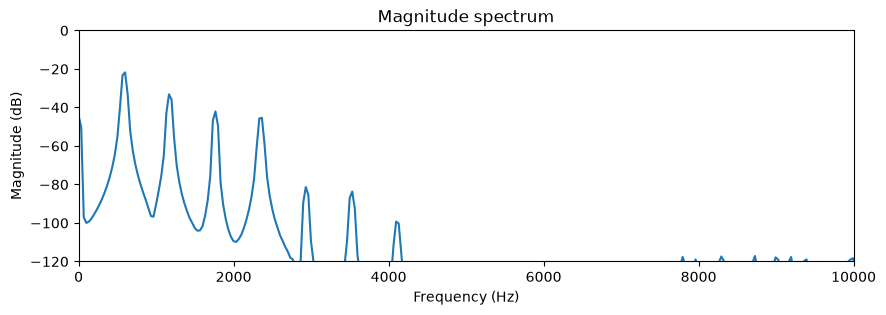

In [17]:
# Write the code here
start = int(0.7 * fs)
end = int(0.73 * fs)
fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 10000])

plt.show()

Choose a time where several harmonics are visible in the spectrogram and plot the spectrum at that time. Can you explain the result?

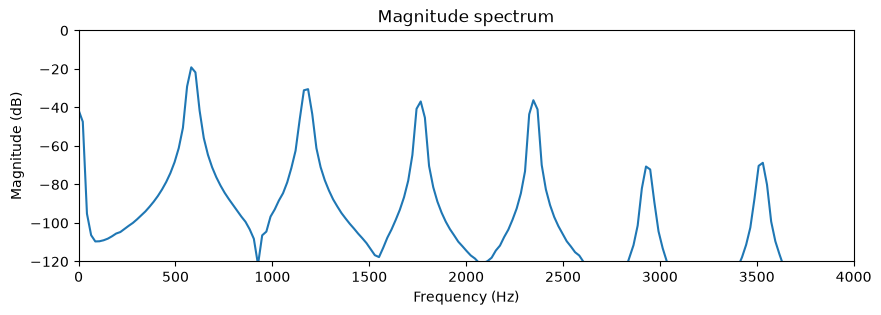

In [19]:
# Write the code here
# Elegimos t = 0.5 segundos, donde hay muchos armónicos visibles en el espectrograma
t_chosen = 0.5  
start = int(t_chosen * fs)
end = start + 2048  # Tamaño del fragmento (n_fft)

fragment = reference_audio[start:end]

ax = plot_spectrum(fragment, sr=fs)
ax.set_ylim([-120, 0])
ax.set_xlim([0, 4000])

plt.show()

Use the plots to estimate the weights of the fundamental frequency and a few harmonics. Store them in a list for later use. Be careful because the amplitude of the plot are in dB and you will need them in a linear scale, from 0 to 1, where 1 should be the maximum value of the spectrum. So you need to perform the conversion from dB to linear.

In [23]:
# Fill this list with the measured weights

import numpy as np

# 1. Picos medidos visualmente del gráfico (en dB)
weights_db = np.array([-19, -30, -37, -36, -70, -68])

# 2. Conversión a escala lineal: 10^(dB / 20)
weights_linear = 10 ** (weights_db / 20)

# 3. Normalización para que el máximo sea 1
weights = (weights_linear / np.max(weights_linear)).tolist()

print(weights)

[1.0, 0.2818382931264453, 0.12589254117941667, 0.1412537544622754, 0.0028183829312644535, 0.003548133892335755]


### 2. Synthesis

Now we will use the harmonic synthesis idea from previous labs to build a signal from the estimated spectral weights.

In [24]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

#### 2.1 Write the code

Use the `synthesize` function to generate a signal with the weights from part 1.3 and the fundamental frequency and phase from earlier labs. Plot the synthesized signal together with the reference so you can compare them directly.

In [26]:
# Write the synthesis code here
f0=588
phi=2.578141307339463

# 2. Definir el mismo fragmento de referencia (t = 0.5 s)
t_start = 0.5
n_samples = 2048  # El tamaño de la ventana usada anteriormente

start_sample = int(t_start * fs)
ref_fragment = reference_audio[start_sample : start_sample + n_samples]

# 3. Crear el vector de tiempo 't' para la duración de este fragmento
t = np.arange(n_samples) / fs

sound = synthesize(f0, phi, weights, t)

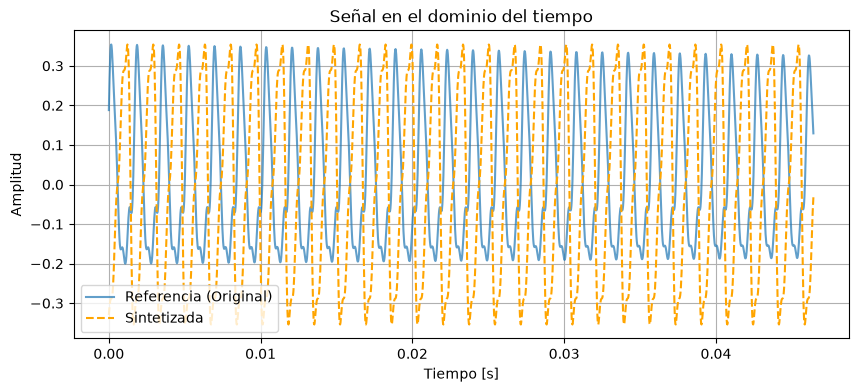

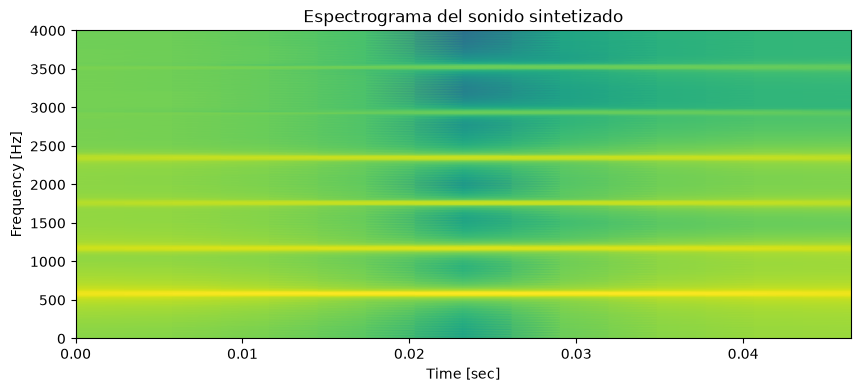

In [28]:
sound = sound * (np.max(np.abs(ref_fragment)) / np.max(np.abs(sound)))
# Write the plotting code here, both time domain and spectrogram
# ==========================================
# 1. DOMINIO DEL TIEMPO (Time domain)
# ==========================================
plt.figure(figsize=(10, 4))
plt.plot(t, ref_fragment, label='Referencia (Original)', alpha=0.7)
plt.plot(t, sound, label='Sintetizada', linestyle='--', color='orange')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.title('Señal en el dominio del tiempo')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 2. ESPECTROGRAMA (Spectrogram)
# ==========================================
# Graficamos el espectrograma del sonido sintetizado
ax = plot_spectrogram(sound, sr=fs, N=2048, H=256)
ax.set_ylim([0, 4000])
plt.title('Espectrograma del sonido sintetizado')
plt.show()

#### 2.2 Questions

1. What do you notice when you compare the synthesized spectrogram with the reference spectrogram?
   - Write your answer here.

2. Which parts of the sound are reproduced well, and which parts are still missing or different?
   - Write your answer here.